# Win Probability computation - Prediction of round outcome 
from Fire-STOMs data pre-extracted into the feature data folder 
|"F:\Research_Data_Public\Esports\CSDATA\DataScience\CS2_Project\FeatData\Wfire_STOMS_01\Training\Inferno"|
For any one match 
- Collapsed aggregated evolution vs. epochs
- overlaid with the win probabilities vs. epocsh (prediction)

Evaluation of prediction performance with ground truth 



--- Available Matches (Feature Data) ---
[0] 2d8be8de-4992-48f4-b9a6-93bd1af479db
[1] 0292031a-0639-42fa-8a8a-0c7007dff72a
[2] 4d08abe6-ab3e-4c59-a826-bb94159686a0
[3] 877ff425-81c6-476d-a39e-0fba8bb3db60
[4] 0189ea4b-ecf3-4798-85f6-b860cf454dc5
[5] 8c051824-c396-4752-b492-6663afb4c892
[6] 25aa296b-7a88-4b6a-8e73-2934bc965681
[7] fcf46095-7de5-4880-9897-6f801814fea9
[8] 499bda87-4703-47cb-8b15-79b23db338c4
[9] 9015fe20-21db-4d5d-a989-4d27c28a4ce2
[10] c07c1831-da98-43a2-b8d1-b7c7bf1ba8c9
[11] 1850a93e-c84f-4fab-bee4-1c78ef26deb4
[12] 4c1fb1e6-8917-4551-a4d0-08e9c1cb1716
[13] 7f18c19f-fc5c-4b74-8021-21f33d8183ff
[14] ee6a97a8-2a18-4a1b-9300-9d6d822da227
[15] 5be0c51c-fb70-4faa-b914-1dd2b036656c
[16] c9064391-70dd-495a-8c3a-7cd8ba041d82
[17] 756c7fcd-9d22-4020-b677-6118b473306e
[18] 539633db-9be7-4ec5-8965-613d62e8c75c
[19] b0ae98c4-5c65-44e5-b52d-45deaf79636e
[20] 7fb64ddd-b522-4eab-add0-bbccdf379641
[21] e725154a-a954-40da-8134-25bab6ab8b11
[22] 204a645c-f0af-4334-85cf-54b631be9523
[2

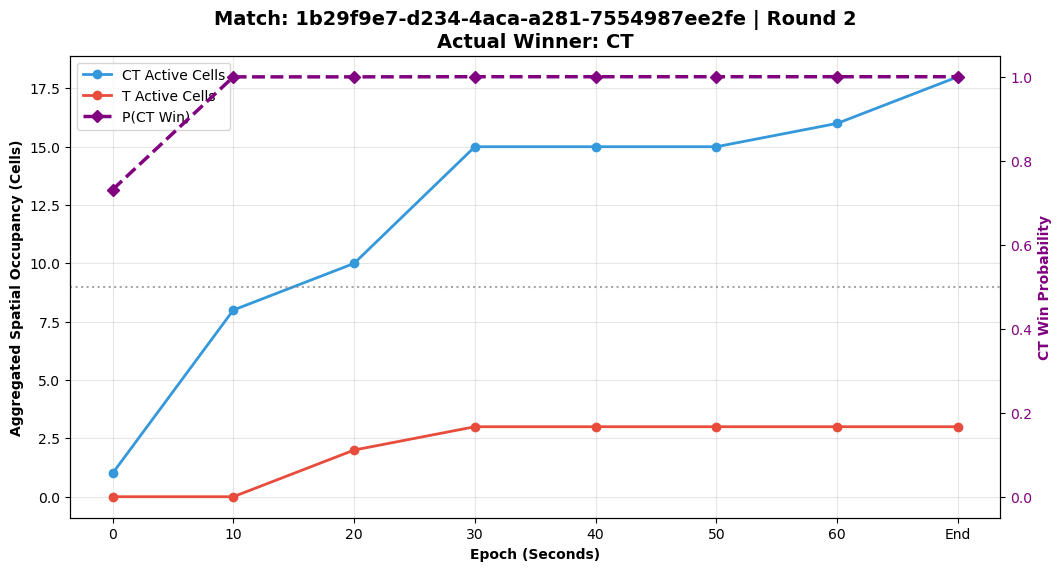

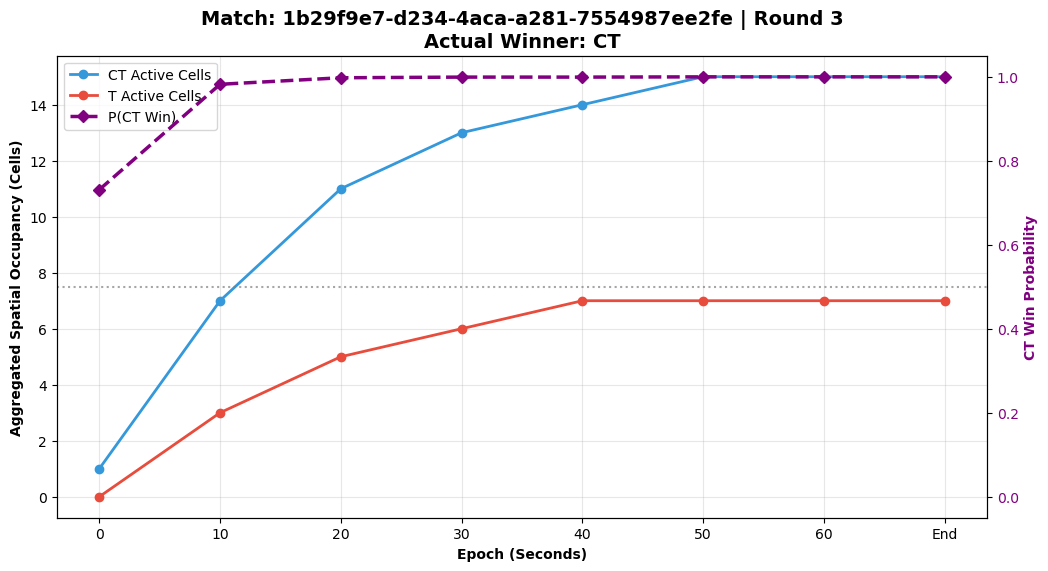

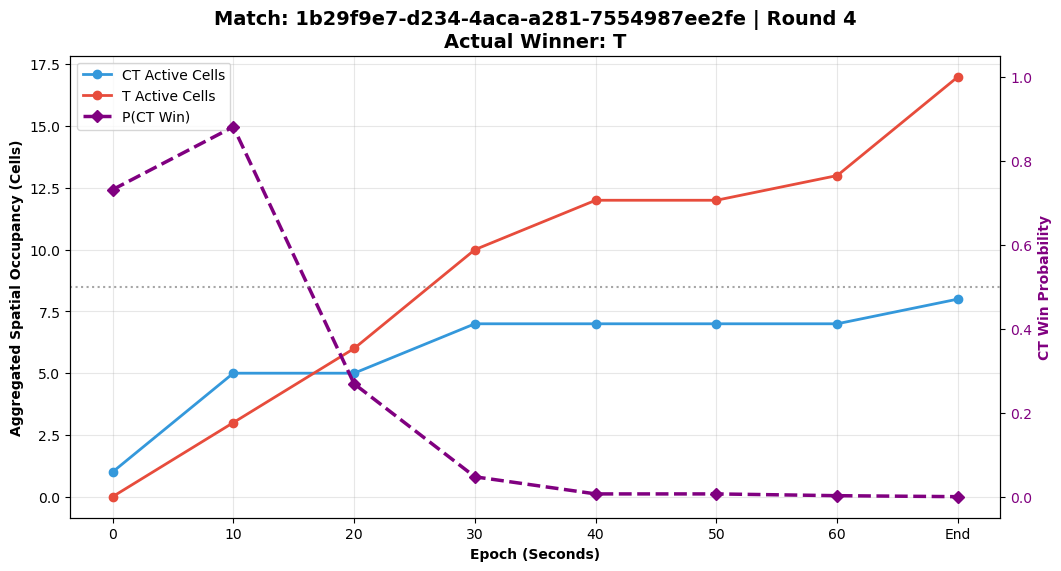

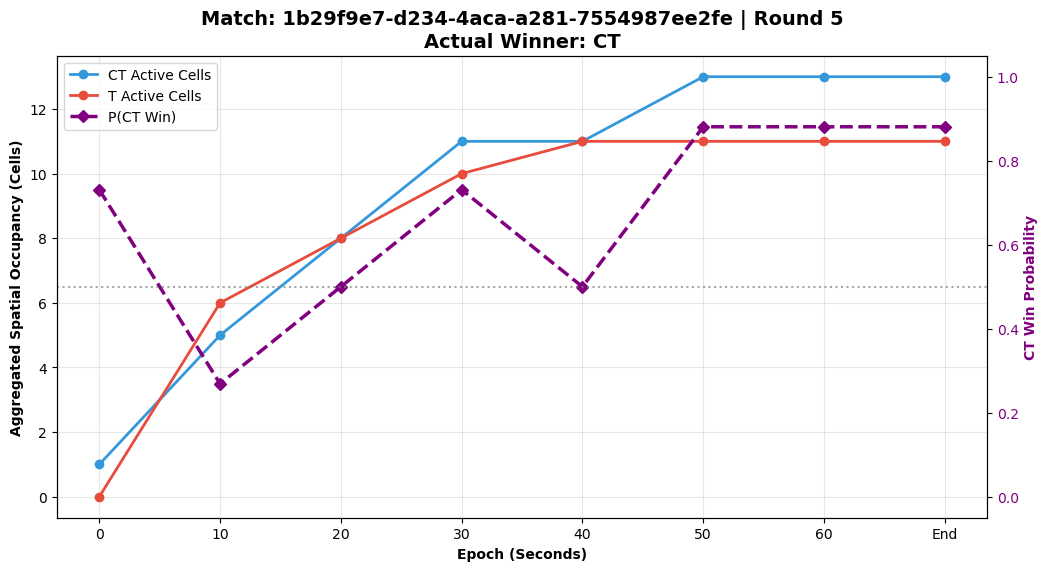

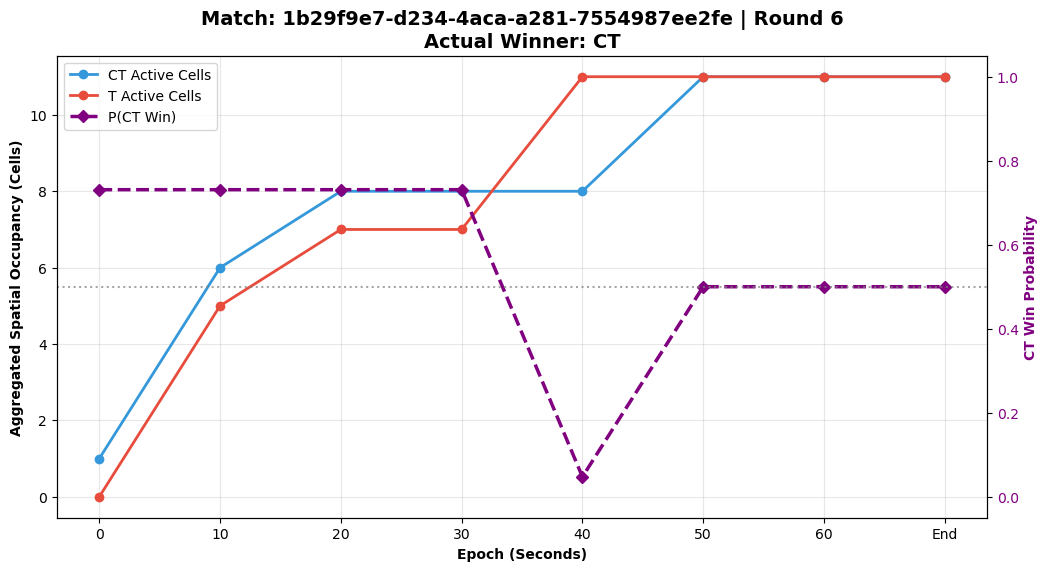

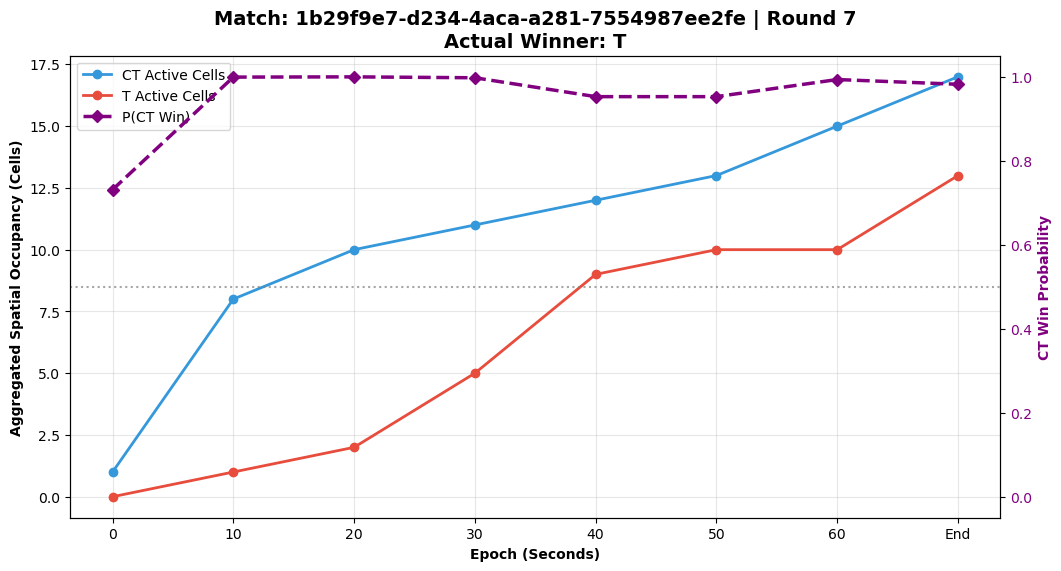

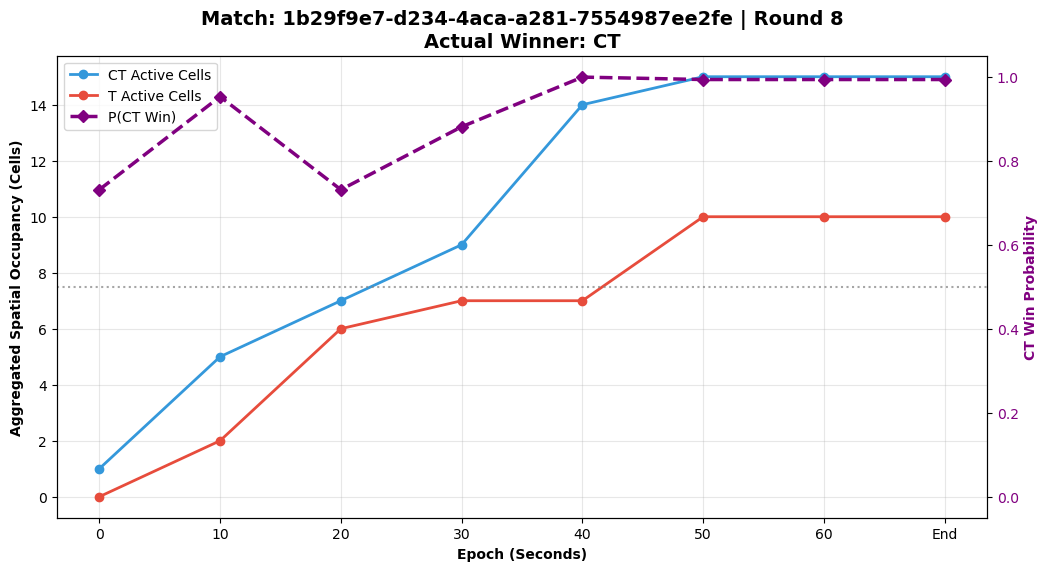

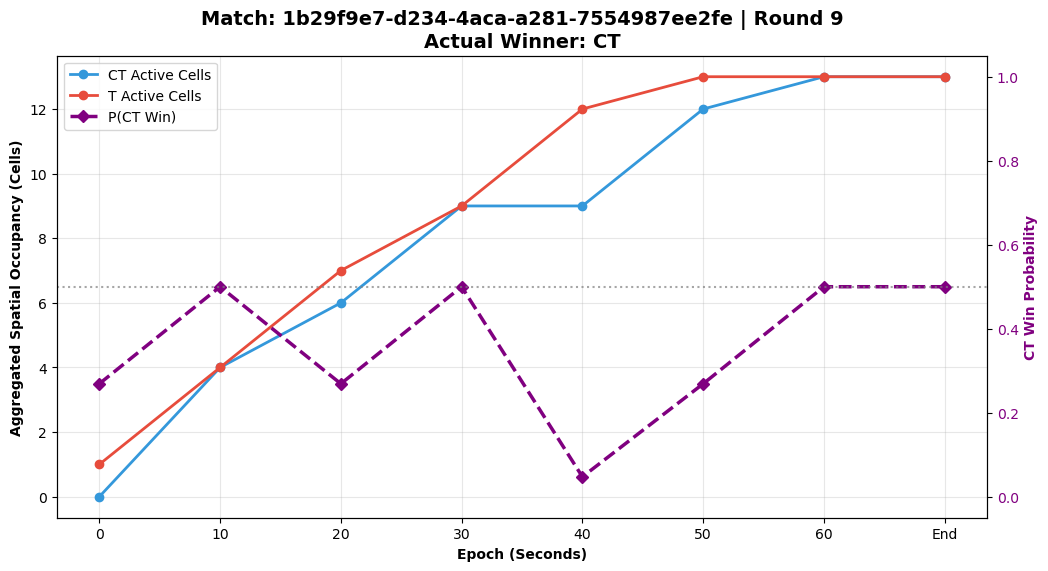

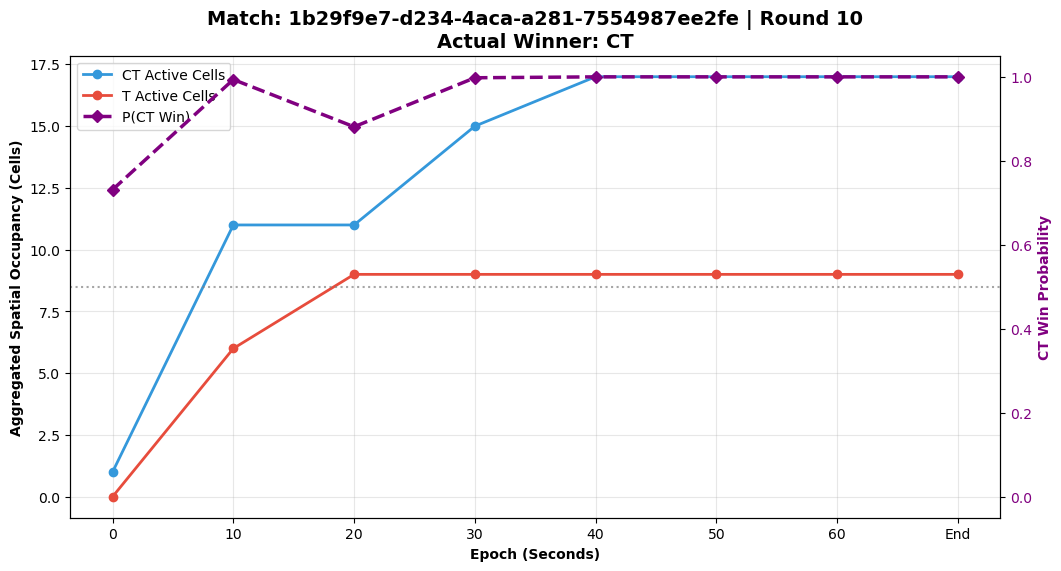

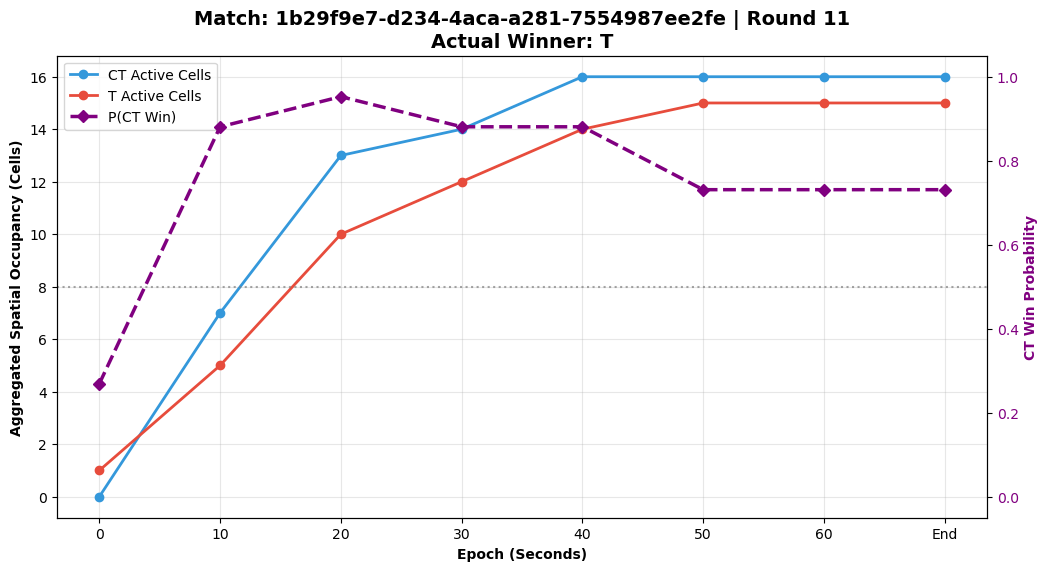

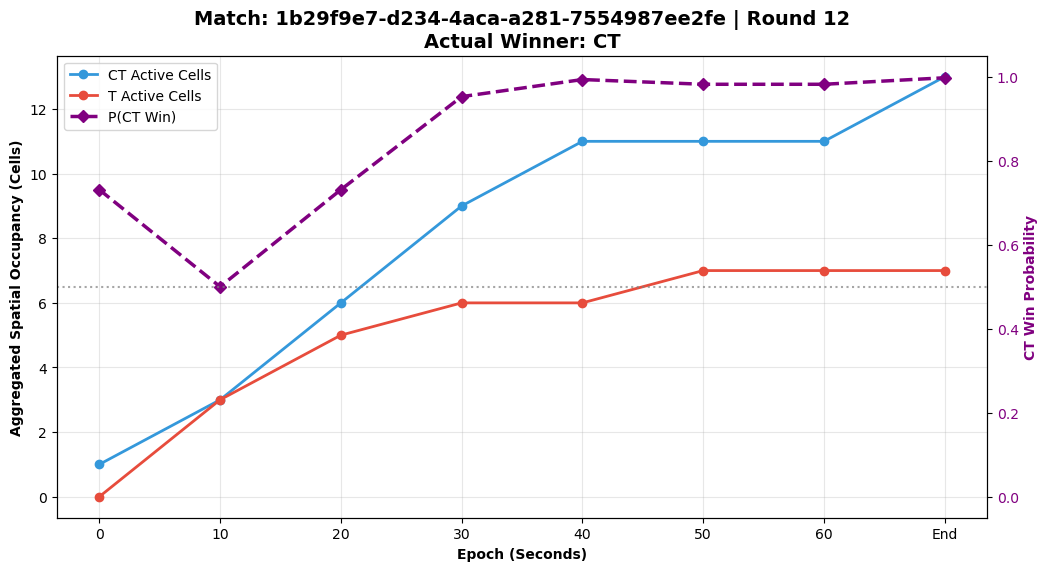

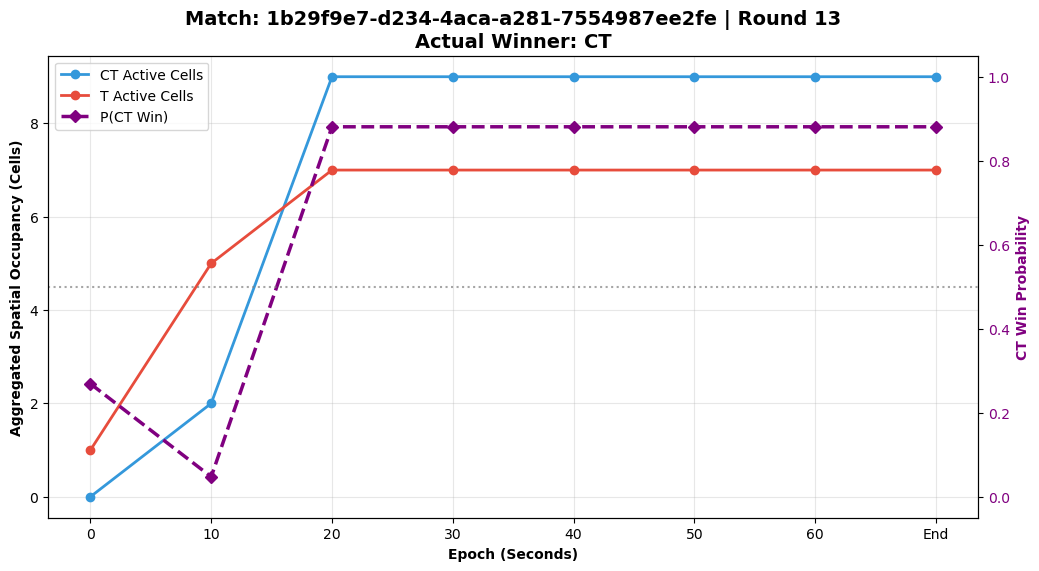

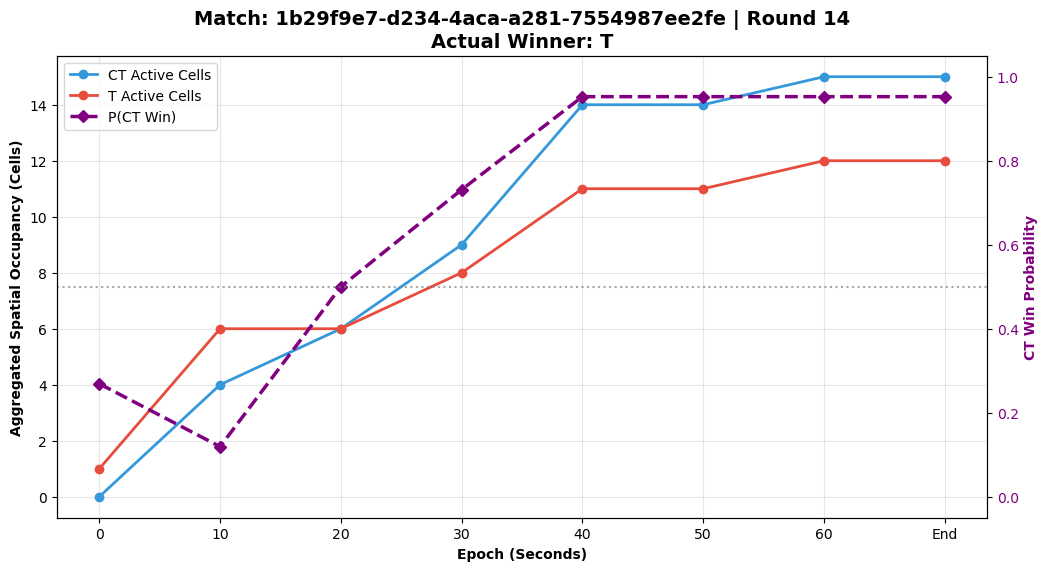

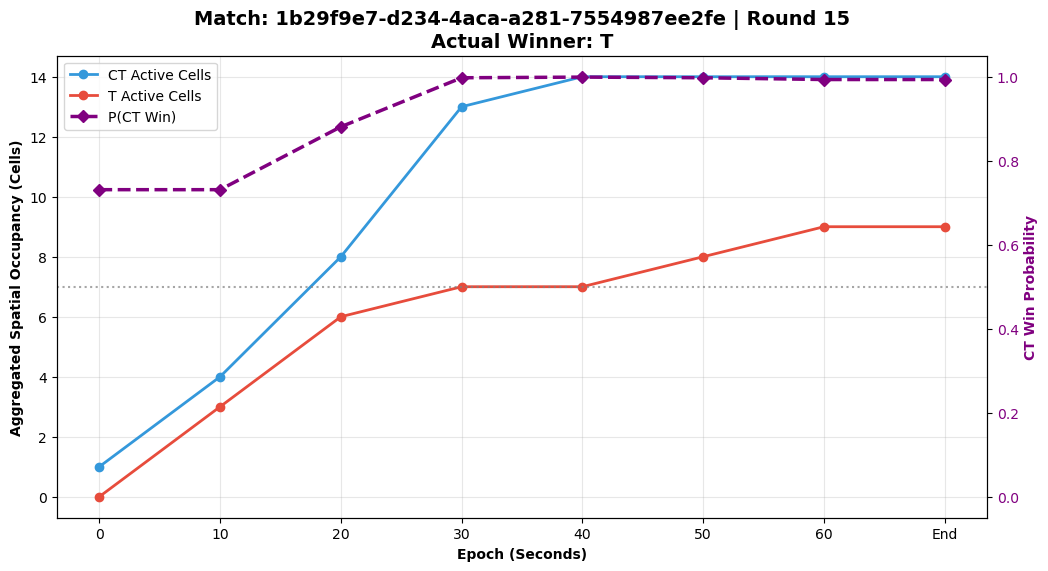

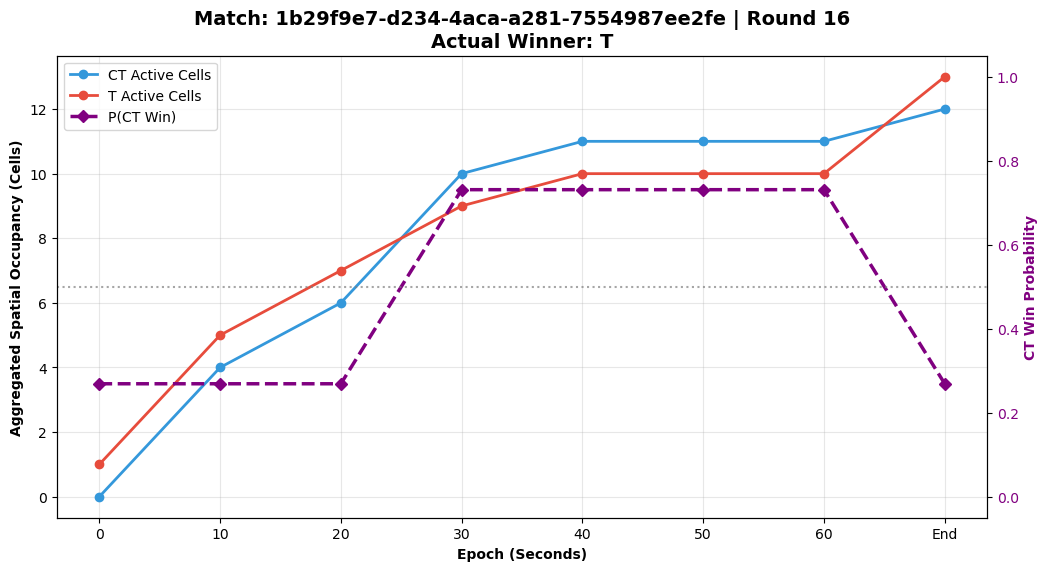

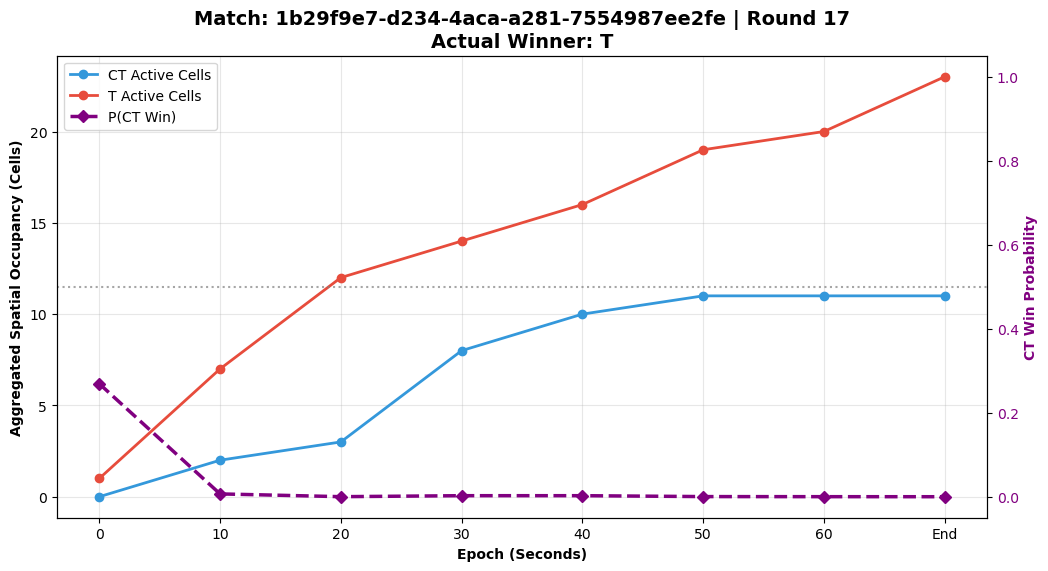

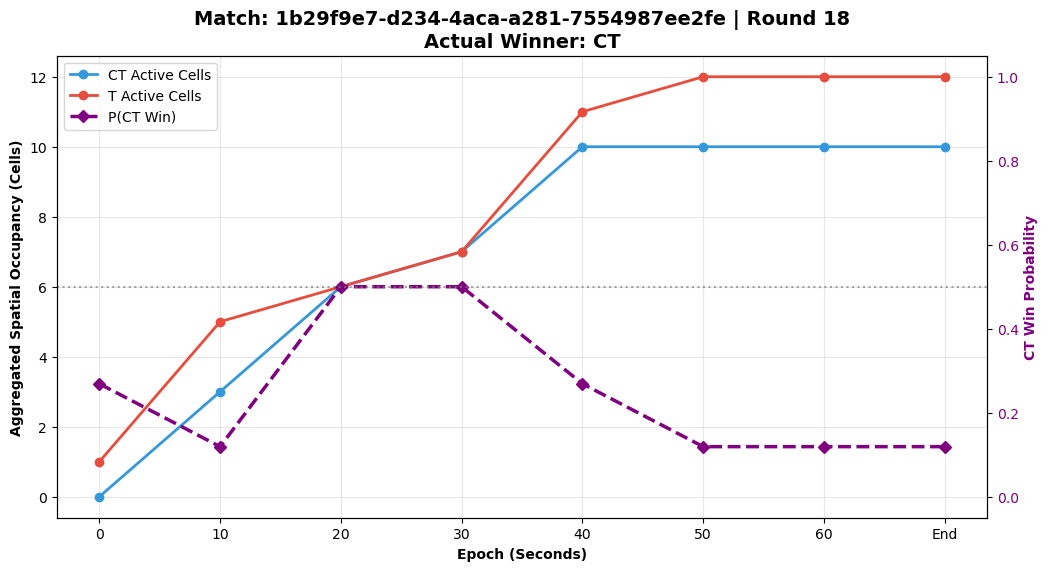

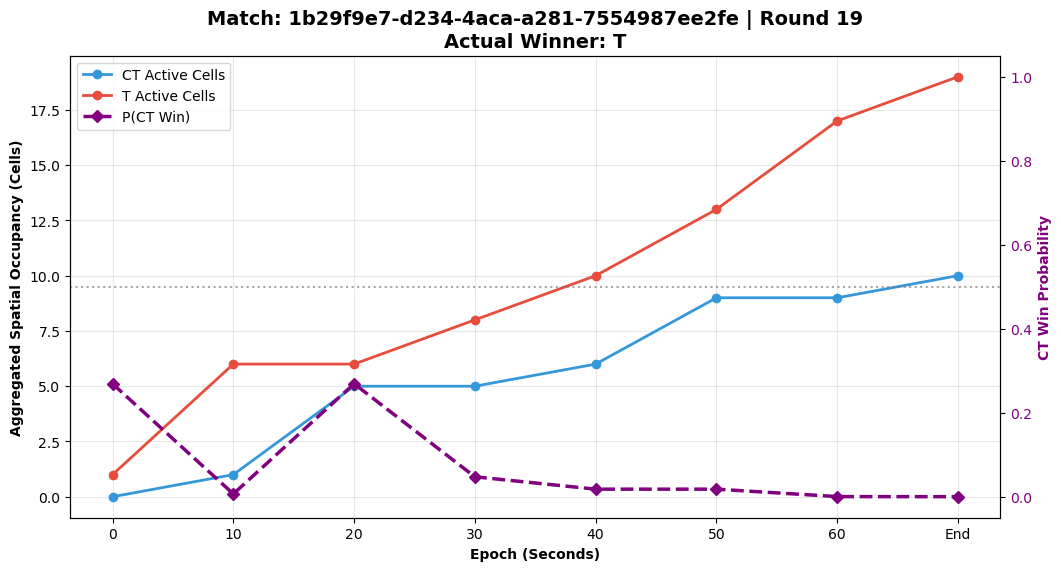


 PREDICTION ACCURACY SUMMARY: 1b29f9e7-d234-4aca-a281-7554987ee2fe
Epoch      | Correct    | Total      | Accuracy
----------------------------------------
0          | 12         | 18         | 66.67%
10         | 9          | 18         | 50.00%
20         | 12         | 18         | 66.67%
30         | 11         | 18         | 61.11%
40         | 9          | 18         | 50.00%
50         | 10         | 18         | 55.56%
60         | 10         | 18         | 55.56%
End        | 11         | 18         | 61.11%



In [1]:
import os
import glob
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ==========================================
# 1. CONFIGURATION & CONSTANTS
# ==========================================
FEAT_DIR = Path(r"D:\Research_Data_Public\Esports\CSDATA\DataScience\CS2_Project\FeatData\Wfire_STOMS_01\Training\Anubis")
RAW_DATA_DIR = Path(r"D:\Research_Data_Public\Esports\CSDATA\datasets\billpureskillgg\cs2-2023-11-23\versions\2\csds")

EPOCHS = [0, 10, 20, 30, 40, 50, 60, "End"]
GRID_SIZE = 10

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# ==========================================
# 2. FILE SELECTION & DATA RETRIEVAL
# ==========================================
def select_match_file():
    """Lists available STOM feature files and prompts user for selection."""
    if not FEAT_DIR.exists():
        print(f"Error: Feature directory does not exist: {FEAT_DIR}")
        return None

    files = list(FEAT_DIR.glob("*.csv"))
    if not files:
        print("No CSV feature files found.")
        return None

    print("\n--- Available Matches (Feature Data) ---")
    for idx, filepath in enumerate(files):
        print(f"[{idx}] {filepath.stem}")

    while True:
        try:
            selection = int(input(f"\nEnter match index [0 to {len(files)-1}]: "))
            if 0 <= selection < len(files):
                return files[selection]
            print("Invalid index.")
        except ValueError:
            print("Please enter a valid number.")

def get_actual_winners(match_id):
    """Finds the raw round_end parquet file to extract ground truth."""
    # Search for the match directory in the raw data path
    match_dirs = list(RAW_DATA_DIR.rglob(match_id))
    if not match_dirs:
        print(f"Warning: Raw data directory for match {match_id} not found.")
        return {}

    match_dir = match_dirs[0]
    re_files = glob.glob(str(match_dir / "round_end*"))
    
    if not re_files:
        print(f"Warning: 'round_end' channel not found for match {match_id}.")
        return {}

    # Load and map winner team codes
    df_end = pl.read_parquet(re_files[0])
    team_map = {"2": "T", "3": "CT", "TERRORIST": "T", "CT": "CT", "T": "T"}
    
    df_end = df_end.with_columns(
        pl.col("winner_team_code").cast(pl.Utf8).replace(team_map).alias("actual_winner")
    ).select(["round", "actual_winner"])
    
    # Return as a dictionary: {round_id: "CT" or "T"}
    return dict(zip(df_end["round"].to_list(), df_end["actual_winner"].to_list()))

# ==========================================
# 3. ANALYSIS & VISUALIZATION
# ==========================================
def run_stom_analysis(filepath):
    match_id = filepath.stem
    print(f"\nProcessing Match: {match_id}")
    
    df_feat = pl.read_csv(filepath)
    actual_winners_map = get_actual_winners(match_id)
    
    rounds = df_feat["round"].to_list()
    
    # Store predictions for match-level evaluation
    # {epoch: {"correct": int, "total": int}}
    eval_metrics = {str(e): {"correct": 0, "total": 0} for e in EPOCHS}

    for r_idx in range(len(rounds)):
        round_data = df_feat.row(r_idx, named=True)
        r_id = round_data["round"]
        actual_winner = actual_winners_map.get(r_id, "Unknown")

        ct_counts = []
        t_counts = []
        ct_probs = []

        # Feature Extraction & Probability Calculation
        for epoch in EPOCHS:
            # Reconstruct occupancy counts (Sum of cells > 0)
            ct_occ = sum(1 for i in range(GRID_SIZE**2) if round_data.get(f"CT_e{epoch}_cell_{i:02d}", 0) > 0)
            t_occ = sum(1 for i in range(GRID_SIZE**2) if round_data.get(f"T_e{epoch}_cell_{i:02d}", 0) > 0)
            
            ct_counts.append(ct_occ)
            t_counts.append(t_occ)
            
            # Prediction: Sigmoid of the difference
            prob_ct = sigmoid(ct_occ - t_occ)
            ct_probs.append(prob_ct)
            
            # Evaluation
            if actual_winner in ["CT", "T"]:
                pred_winner = "CT" if prob_ct > 0.5 else "T"
                eval_metrics[str(epoch)]["total"] += 1
                if pred_winner == actual_winner:
                    eval_metrics[str(epoch)]["correct"] += 1

        # --------------------------------------------------
        # Visualization: Collapsed Temporal Plot
        # --------------------------------------------------
        fig, ax1 = plt.subplots(figsize=(12, 6))
        x_labels = [str(e) for e in EPOCHS]

        # Primary Axis: Accumulated Map Control (Weapon Fire Cells)
        ax1.plot(x_labels, ct_counts, marker='o', color='#3498db', label='CT Active Cells', linewidth=2)
        ax1.plot(x_labels, t_counts, marker='o', color='#e74c3c', label='T Active Cells', linewidth=2)
        ax1.set_xlabel("Epoch (Seconds)", fontweight='bold')
        ax1.set_ylabel("Aggregated Spatial Occupancy (Cells)", fontweight='bold')
        ax1.grid(True, alpha=0.3)
        
        # Secondary Axis: CT Win Probability Overlay
        ax2 = ax1.twinx()
        ax2.plot(x_labels, ct_probs, marker='D', color='purple', linestyle='--', label='P(CT Win)', linewidth=2.5)
        ax2.set_ylabel("CT Win Probability", fontweight='bold', color='purple')
        ax2.set_ylim(-0.05, 1.05)
        ax2.axhline(0.5, color='gray', linestyle=':', alpha=0.7)
        ax2.tick_params(axis='y', labelcolor='purple')

        # Combine Legends
        lines_1, labels_1 = ax1.get_legend_handles_labels()
        lines_2, labels_2 = ax2.get_legend_handles_labels()
        ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left')

        plt.title(f"Match: {match_id} | Round {r_id}\nActual Winner: {actual_winner}", fontsize=14, fontweight='bold')
        plt.show()

    # --------------------------------------------------
    # 4. Final Evaluation Printout
    # --------------------------------------------------
    print("\n" + "="*40)
    print(f" PREDICTION ACCURACY SUMMARY: {match_id}")
    print("="*40)
    print(f"{'Epoch':<10} | {'Correct':<10} | {'Total':<10} | {'Accuracy'}")
    print("-" * 40)
    for epoch in EPOCHS:
        data = eval_metrics[str(epoch)]
        total = data["total"]
        if total > 0:
            acc = (data["correct"] / total) * 100
            print(f"{str(epoch):<10} | {data['correct']:<10} | {total:<10} | {acc:.2f}%")
        else:
            print(f"{str(epoch):<10} | N/A")
    print("="*40 + "\n")

# ==========================================
# MAIN EXECUTION
# ==========================================
if __name__ == "__main__":
    selected_file = select_match_file()
    if selected_file:
        run_stom_analysis(selected_file)